# Taller 2. Predicción de abandono (churn) de clientes
## Notebook 3 de 3. Generación de valor

**MINE-4101 Ciencia de Datos Aplicada, Universidad de los Andes, 2026-20**

**Integrantes:**
* Lina Muñoz (202310172)
* Yair Andrade (202310241)

**Requisito.** Ejecutar antes `01_entendimiento_preparacion.ipynb`, que genera `data/churn_limpio.csv`.

**Pregunta.** ¿Cuánto gana un banco colombiano promedio si usa el modelo para decidir a quién ofrecerle una campaña de retención, y cuándo recupera la inversión?

**Contenido**
* 0. Configuración
* 5. Generación de valor
  * 5.1 Planteamiento
  * 5.2 Supuestos
  * 5.3 Modelos
  * 5.4 Del 20% de la muestra al 15% del banco
  * 5.5 Elección del umbral (validación)
  * 5.6 Ganancia esperada (prueba)
  * 5.7 Retorno y punto de equilibrio
  * 5.8 Sensibilidad
  * 5.9 Limitaciones
  * 5.10 Conclusiones

## 0. Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

SEED = 42
HORIZONTE = 36  # meses para el VPN


def millones(valor):
    """Escribe un valor en pesos como millones de COP: 380400000 -> 'COP 380,4 M'."""
    return f"COP {valor / 1e6:.1f} M".replace(".", ",")


def porcentaje(valor):
    """Escribe una proporción como porcentaje: 0.147 -> '14,7%'."""
    return f"{valor * 100:.1f}%".replace(".", ",")


def miles(valor):
    """Escribe un número entero con punto de miles: 20000 -> '20.000'."""
    return f"{valor:,.0f}".replace(",", ".")

## 5. Generación de valor

### 5.1 Planteamiento

El modelo genera valor cuando el banco lo usa para decidir a quién contactar. Cada contacto se paga. Si el cliente se iba a ir, la oferta lo retiene con una probabilidad de 30%. Si se iba a quedar, el contacto no cambia nada.

`Ganancia anual de la campaña = retenidos × valor de un cliente retenido − contactados × costo por contacto`

A esa ganancia se le resta lo que cuesta implementar el modelo (una vez) y operarlo (cada año).

Comparamos contra dos opciones sin modelo: **no hacer campaña** (ganancia 0) y **contactar a todos** los clientes.

El umbral se elige con los datos de **validación** y la ganancia se mide con los de **prueba**, que no se usan para decidir nada.

### 5.2 Supuestos

Cada supuesto tiene un valor base y un rango (bajo y alto) que usamos después en el análisis de sensibilidad. La última columna dice cuánto confiamos en cada valor: **alta** si viene de una fuente oficial o académica, **media** si la fuente es seria pero indirecta y **baja** si viene de un proveedor, de una cadena de citas débil o es un supuesto nuestro. Las fuentes se consultaron el 7 de noviembre de 2026.

| Supuesto | Bajo | Base | Alto | Fuente | Confianza |
|---|---|---|---|---|---|
| Clientes del banco | | 20.000 | | Enunciado | — |
| Tasa de churn anual | 10% | 15% | 20% | Enunciado; [ReviewTrackers](https://www.reviewtrackers.com/blog/bank-customer-retention/) | Baja |
| Efectividad de la oferta | 15% | 30% | 48% | Enunciado; [Höppner et al. (2017)](https://arxiv.org/abs/1712.08101) | Media |
| Ingreso anual por cliente | COP 500.000 | COP 700.000 | COP 900.000 | Enunciado; [reporte de Nu, 1T 2026](https://www.sec.gov/Archives/edgar/data/1691493/000129281426003055/nu20260514_6k.htm) | Media |
| Margen de contribución | 25% | 35% | 45% | [Reporte de Nu, 1T 2026](https://www.sec.gov/Archives/edgar/data/1691493/000129281426003055/nu20260514_6k.htm) | Media |
| Tasa de descuento anual | 12,25% | 16,5% | 20% | [Banco de la República](https://www.banrep.gov.co/es/noticias/calendario-actividades-junta-directiva/reunion-octubre-2026), [La República](https://www.larepublica.co/economia/los-tes-a-10-anos-superan-13-y-colombia-tiene-mayor-riesgo-pais-que-brasil-y-mexico-4507217), [Damodaran](https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/ctryprem.html) | Media |
| Costo por cliente contactado | COP 15.000 | COP 40.000 | COP 115.000 | [FusionCX](https://www.fusioncx.com/blog/locations/colombia/colombia-call-center-costs-2026-b2b-buyer-guide/), [Bancolombia](https://www.bancolombia.com/personas/tarifario/tarjeta-de-credito) | Baja |
| Costo de implementación | COP 35 M | COP 130 M | COP 400 M | [Indeed](https://co.indeed.com/career/data-scientist/salaries), [Levels.fyi](https://www.levels.fyi/es/t/data-scientist/locations/colombia), [Gerencie](https://www.gerencie.com/porcentajes-prestaciones-sociales.html) | Media |
| Meses de implementación | 4 | 6 | 8 | [Gartner](https://www.gartner.com/en/newsroom/press-releases/2024-05-07-gartner-survey-finds-generative-ai-is-now-the-most-frequently-deployed-ai-solution-in-organizations) | Media |
| Costo de operación anual | COP 12 M | COP 50 M | COP 140 M | Supuesto propio | Baja |

**De dónde sale cada valor**

* **Churn.** El 15% es el del enunciado. Viene de un artículo de ReviewTrackers que lo atribuye a FI Works, sin un estudio detrás; por eso la confianza es baja. El rango de 10% a 20% es nuestro.
* **Efectividad de la oferta.** El 30% del enunciado coincide con lo que proponen Verbraken, Verbeke y Baesens (2013) para campañas de retención: una distribución Beta(6, 14), cuyo promedio es 30%. Sus percentiles 5 y 95 son el valor bajo y el alto. Es un supuesto pensado para empresas de telecomunicaciones, no una medición en bancos.
* **Ingreso y margen.** Tomamos el punto medio del rango del enunciado, que coincide con lo que Nu gana por cliente activo: US$15,9 al mes, unos COP 708.500 al año. En el mismo reporte, la utilidad bruta es el 35% del ingreso; ese es el margen. Nu es un neobanco y no un banco promedio, por eso la confianza es media.
* **Tasa de descuento.** Es el costo del patrimonio calculado con el modelo CAPM: el rendimiento del TES a 10 años (13,18%) más una prima por riesgo. Según cómo se cuente el riesgo país, da entre 16,4% y 16,7%, así que usamos 16,5%. El valor bajo es la tasa del Banco de la República (12,25%) y el alto suma un riesgo por ejecutar el proyecto.
* **Costo por contacto.** Es una llamada más un incentivo. Según FusionCX, un agente de call center en Colombia cuesta entre US$12 y 20 la hora; tomamos el valor más bajo porque esa tarifa es para agentes bilingües, y con 4 contactos por hora cada llamada cuesta unos COP 9.700. El incentivo es un mes gratis de cuota de manejo de la tarjeta de crédito, COP 30.900 en Bancolombia. El valor bajo es un contacto digital y el alto, una llamada más cara con tres meses gratis.
* **Implementación y operación.** Implementar es el trabajo de 1,5 personas durante 6 meses, con un salario de COP 10 M al mes (entre los COP 6,1 M de Indeed y los 13,1 M de Levels.fyi) y 45% de carga prestacional. Según Gartner, un proyecto de IA tarda unos 8 meses en llegar a producción; usamos 6 porque el modelo ya existe. Operarlo es un cuarto del tiempo de una persona más unos US$200 al mes de nube.
* **Tipo de cambio.** Solo sirve para pasar dólares a pesos. Para el ingreso de Nu usamos la TRM de su reporte (3.713, marzo de 2026) y para los costos, la de noviembre (3.238). Con la de noviembre, el ingreso de Nu sería unos COP 618.000, todavía dentro del rango.

**Valor de un cliente retenido.** Un cliente retenido se queda varios años, y de su ingreso el banco solo conserva el margen. Por eso se valora con el valor de vida del cliente (CLV):

`CLV = ingreso anual × margen × (1 + d) / (1 + d − r)`

donde `r = 1 − tasa de churn` es la probabilidad de que el cliente siga un año más y `d` es la tasa de descuento.

In [2]:
SUPUESTOS = {
    "n_clientes": 20_000,
    "tasa_churn": 0.15,
    "tasa_exito": 0.30,
    "ingreso_anual": 700_000,
    "margen": 0.35,
    "tasa_descuento": 0.165,
    "costo_contacto": 40_000,
    "costo_implementacion": 130_000_000,
    "meses_implementacion": 6,
    "costo_operacion_anual": 50_000_000,
}

# Valor bajo y valor alto de cada supuesto, para el análisis de sensibilidad.
RANGOS = {
    "tasa_churn": (0.10, 0.20),
    "tasa_exito": (0.15, 0.48),
    "ingreso_anual": (500_000, 900_000),
    "margen": (0.25, 0.45),
    "tasa_descuento": (0.1225, 0.20),
    "costo_contacto": (15_000, 115_000),
    "costo_implementacion": (35_000_000, 400_000_000),
    "meses_implementacion": (4, 8),
    "costo_operacion_anual": (12_000_000, 140_000_000),
}


def valor_cliente_retenido(sup):
    """CLV: valor presente del margen que deja un cliente mientras siga en el banco."""
    margen_anual = sup["ingreso_anual"] * sup["margen"]
    permanencia = 1 - sup["tasa_churn"]
    d = sup["tasa_descuento"]
    return margen_anual * (1 + d) / (1 + d - permanencia)


clv = valor_cliente_retenido(SUPUESTOS)
precision_minima = SUPUESTOS["costo_contacto"] / (SUPUESTOS["tasa_exito"] * clv)
print("Valor de un cliente retenido (CLV): COP", miles(clv))
print("Precisión mínima para que contactar sea rentable:", porcentaje(precision_minima))

Valor de un cliente retenido (CLV): COP 906.111
Precisión mínima para que contactar sea rentable: 14,7%


* Un cliente retenido vale unos **COP 906.000**, cerca de 3,7 años de margen.
* **Precisión mínima de 14,7%.** Un contacto cuesta COP 40.000 y, si el cliente se iba a ir, devuelve en promedio 30% × COP 906.000 ≈ COP 272.000. Contactar a un cliente es rentable solo si la probabilidad de que se vaya supera 40.000 / 272.000 = 14,7%.
* Como el churn del banco (15%) está casi en ese límite, contactar a todos casi no deja ganancia. El valor del modelo está en concentrar los contactos en los clientes de mayor riesgo.

### 5.3 Modelos

Random Forest y Gradient Boosting reentrenados con los hiperparámetros de la sección 2.7 del notebook 2, con la misma división y la misma semilla.

In [3]:
df = pd.read_csv("data/churn_limpio.csv")
df = pd.get_dummies(df, columns=["country", "gender"], dtype=int)

ATRIBUTOS = [
    "credit_score", "age", "tenure", "balance", "products_number",
    "credit_card", "active_member", "estimated_salary",
    "country_France", "country_Germany", "country_Spain",
    "gender_Female", "gender_Male",
]
X = df[ATRIBUTOS]
y = df["churn"]

# Misma división 60/20/20 y misma semilla del notebook 2.
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
y_val = y_val.to_numpy()
y_test = y_test.to_numpy()

# Hiperparámetros encontrados en la sección 2.7 del notebook 2.
modelos = {
    "Random Forest": RandomForestClassifier(
        n_estimators=500, max_depth=15, min_samples_leaf=5, max_features=0.5,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.01, max_depth=6, max_iter=500, min_samples_leaf=20,
        l2_regularization=1, class_weight="balanced", random_state=SEED),
}

prob_val = {}
prob_test = {}
filas = []
for nombre, estimador in modelos.items():
    pipeline = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", estimador),
    ])
    pipeline.fit(X_train, y_train)
    prob_val[nombre] = pipeline.predict_proba(X_val)[:, 1]
    prob_test[nombre] = pipeline.predict_proba(X_test)[:, 1]

    prediccion = prob_test[nombre] >= 0.5
    filas.append({
        "modelo": nombre,
        "F1": f1_score(y_test, prediccion),
        "Precisión": precision_score(y_test, prediccion),
        "Recall": recall_score(y_test, prediccion),
        "ROC-AUC": roc_auc_score(y_test, prob_test[nombre]),
    })

pd.DataFrame(filas).set_index("modelo").round(3)

,F1,Precisión,Recall,ROC-AUC
modelo,,,,
Random Forest,0.633,0.673,0.597,0.867
Gradient Boosting,0.600,0.504,0.742,0.867


Con umbral 0,5, las métricas difieren de las del notebook 2 solo en el tercer decimal (F1 de 0,633 frente a 0,637; ver la nota de reproducibilidad en la sección 3.3 del notebook 2). Los dos modelos tienen el mismo ROC-AUC (0,867): ordenan igual de bien a los clientes por riesgo.

### 5.4 Del 20% de la muestra al 15% del banco

La muestra tiene 20% de churn y el banco, 15%. Con menos clientes que se van, hay más falsas alarmas por cada acierto, así que la matriz de confusión de la muestra no se puede usar tal cual.

Por eso se usan dos tasas que no dependen del churn:
* **TPR (recall):** de los clientes que se van, qué fracción manda a contactar el modelo.
* **FPR:** de los clientes que se quedan, qué fracción manda a contactar el modelo.

En el banco, los verdaderos positivos son TPR × 3.000 y los falsos positivos, FPR × 17.000. Esto supone que los clientes que se van, y los que se quedan, se parecen a los de la muestra.

In [4]:
def tasas(y_real, prob, umbral):
    """TPR: fracción de los que se van que se contactan. FPR: fracción de los que se quedan que se contactan."""
    contactar = prob >= umbral
    tpr = contactar[y_real == 1].mean()
    fpr = contactar[y_real == 0].mean()
    return tpr, fpr


def evaluar_campana(tpr, fpr, sup):
    """Lleva las tasas a un banco con los supuestos dados y calcula la ganancia anual de la campaña."""
    se_van = sup["n_clientes"] * sup["tasa_churn"]
    se_quedan = sup["n_clientes"] - se_van
    verdaderos_positivos = tpr * se_van
    contactados = verdaderos_positivos + fpr * se_quedan
    retenidos = sup["tasa_exito"] * verdaderos_positivos
    valor_retenido = retenidos * valor_cliente_retenido(sup)
    costo_campana = contactados * sup["costo_contacto"]
    return {
        "contactados": contactados,
        "verdaderos_positivos": verdaderos_positivos,
        "retenidos": retenidos,
        "valor_retenido": valor_retenido,
        "costo_campana": costo_campana,
        "ganancia": valor_retenido - costo_campana,
    }


tpr, fpr = tasas(y_test, prob_test["Random Forest"], 0.5)
campana = evaluar_campana(tpr, fpr, SUPUESTOS)
print("Random Forest con umbral 0,5")
print("  Precisión en la muestra de prueba (churn de 20%):", porcentaje(precision_score(y_test, prob_test["Random Forest"] >= 0.5)))
print("  Precisión en el banco (churn de 15%):", porcentaje(campana["verdaderos_positivos"] / campana["contactados"]))

Random Forest con umbral 0,5
  Precisión en la muestra de prueba (churn de 20%): 67,3%
  Precisión en el banco (churn de 15%): 58,7%


Con umbral 0,5, la precisión baja de 67,3% en la muestra a **58,7% en el banco**. Sigue muy por encima del mínimo de 14,7%: conviene bajar el umbral y contactar a más clientes.

### 5.5 Elección del umbral (validación)

Para cada umbral entre 0 y 1 calculamos la ganancia anual en el banco con los clientes de validación, y elegimos el umbral que la maximiza.

Random Forest: umbral óptimo 0.3, ganancia en validación COP 376,4 M
Gradient Boosting: umbral óptimo 0.53, ganancia en validación COP 380,8 M


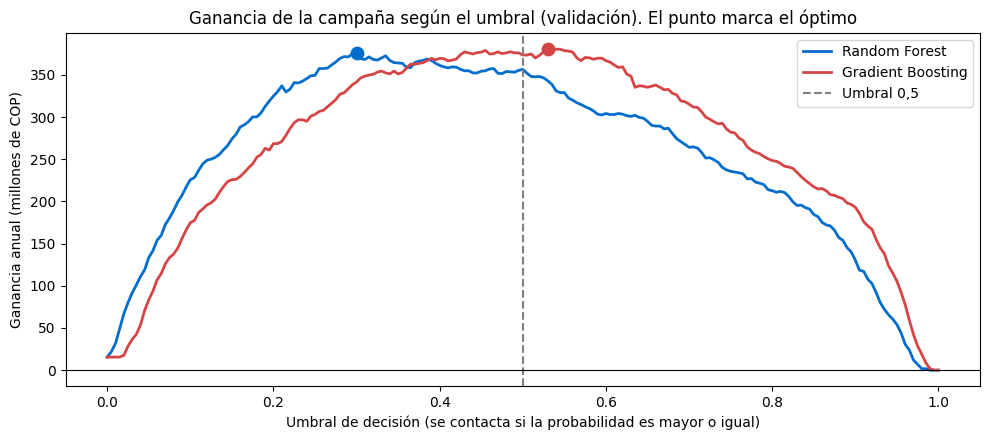

In [5]:
# Umbrales de 0 a 1 cada 0,005. El 1,01 no lo alcanza ningún cliente: es la opción de no contactar a nadie.
UMBRALES = np.append(np.round(np.arange(0, 1.001, 0.005), 3), 1.01)


def tasas_por_umbral(y_real, prob):
    """TPR y FPR para cada umbral de la lista UMBRALES."""
    lista_tpr = []
    lista_fpr = []
    for umbral in UMBRALES:
        tpr, fpr = tasas(y_real, prob, umbral)
        lista_tpr.append(tpr)
        lista_fpr.append(fpr)
    return np.array(lista_tpr), np.array(lista_fpr)


umbral_optimo = {}
ganancia_val = {}
for nombre in modelos:
    tpr, fpr = tasas_por_umbral(y_val, prob_val[nombre])
    ganancia_val[nombre] = evaluar_campana(tpr, fpr, SUPUESTOS)["ganancia"]
    mejor = np.argmax(ganancia_val[nombre])
    umbral_optimo[nombre] = UMBRALES[mejor]
    print(f"{nombre}: umbral óptimo {umbral_optimo[nombre]}, ganancia en validación {millones(ganancia_val[nombre][mejor])}")

colores = {"Random Forest": "#026DCC", "Gradient Boosting": "#D64545"}
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre in modelos:
    ax.plot(UMBRALES[:-1], ganancia_val[nombre][:-1] / 1e6, color=colores[nombre], linewidth=2, label=nombre)
    mejor = np.argmax(ganancia_val[nombre])
    ax.scatter(UMBRALES[mejor], ganancia_val[nombre][mejor] / 1e6, color=colores[nombre], s=80, zorder=3)
ax.axvline(0.5, color="gray", linestyle="--", label="Umbral 0,5")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Umbral de decisión (se contacta si la probabilidad es mayor o igual)")
ax.set_ylabel("Ganancia anual (millones de COP)")
ax.set_title("Ganancia de la campaña según el umbral (validación). El punto marca el óptimo")
ax.legend()
plt.tight_layout()
plt.show()

* El Random Forest maximiza la ganancia con un umbral de **0,30** y el Gradient Boosting con uno de **0,53**. Los umbrales son distintos porque cada modelo reparte la probabilidad a su manera, pero las ganancias son casi iguales (COP 376 M y 381 M).
* Cerca del máximo la curva es casi plana: equivocarse un poco al elegir el umbral cuesta poco.

### 5.6 Ganancia esperada (prueba)

Aplicamos a los clientes de prueba los umbrales elegidos y comparamos cinco políticas.

In [6]:
politicas = [
    ("Sin campaña", 0.0, 0.0),
    ("Contactar a todos", 1.0, 1.0),
]
for nombre, umbral in [("Random Forest", 0.5),
                       ("Random Forest", umbral_optimo["Random Forest"]),
                       ("Gradient Boosting", umbral_optimo["Gradient Boosting"])]:
    tpr, fpr = tasas(y_test, prob_test[nombre], umbral)
    etiqueta = f"{nombre}, umbral {umbral}".replace(".", ",")
    politicas.append((etiqueta, tpr, fpr))

filas = []
for etiqueta, tpr, fpr in politicas:
    c = evaluar_campana(tpr, fpr, SUPUESTOS)
    if c["contactados"] > 0:
        precision_banco = c["verdaderos_positivos"] / c["contactados"]
    else:
        precision_banco = None
    filas.append({
        "política": etiqueta,
        "contactados": round(c["contactados"]),
        "se iban a ir": round(c["verdaderos_positivos"]),
        "retenidos": round(c["retenidos"]),
        "precisión en el banco": precision_banco,
        "valor retenido (M COP)": c["valor_retenido"] / 1e6,
        "costo contactos (M COP)": c["costo_campana"] / 1e6,
        "ganancia anual (M COP)": c["ganancia"] / 1e6,
        "ganancia por cliente evaluado (COP)": round(c["ganancia"] / SUPUESTOS["n_clientes"]),
    })

pd.DataFrame(filas).set_index("política").round(3)

,contactados,se iban a ir,retenidos,precisión en el banco,valor retenido (M COP),costo contactos (M COP),ganancia anual (M COP),ganancia por cliente evaluado (COP)
política,,,,,,,,
Sin campaña,0,0,0,NaN,0.000,0.000,0.000,0
Contactar a todos,20000,3000,900,0.150,815.500,800.000,15.500,775
"Random Forest, umbral 0,5",3050,1791,537,0.587,486.896,122.017,364.879,18244
"Random Forest, umbral 0,3",7121,2447,734,0.344,665.224,284.855,380.369,19018
"Gradient Boosting, umbral 0,53",4833,2123,637,0.439,577.061,193.338,383.723,19186


Con el **Random Forest y umbral 0,30**, en el banco de 20.000 clientes:
* Se contacta a **7.121 clientes** (36% de la base), de los cuales 2.447 se iban a ir. La precisión es de 34,4%: 1 de cada 3 contactados se iba a ir, más del doble del mínimo.
* Se retiene a **734 clientes** al año. El churn baja de 15% a 11,3%.
* La campaña gana **COP 380,4 M al año** (COP 665,2 M de valor retenido menos COP 284,9 M de contactos), es decir, **COP 19.018 por cliente evaluado**.
* Sin modelo, la mejor opción es contactar a todos, que deja apenas COP 15,5 M.

**Incertidumbre (bootstrapping).** La ganancia sale de solo 2.000 clientes de prueba. Remuestreamos esos clientes 2.000 veces con reemplazo y recalculamos la ganancia con los umbrales ya elegidos.

In [7]:
def ganancia(y_real, prob, umbral):
    """Ganancia anual de la campaña en el banco con un umbral dado."""
    tpr, fpr = tasas(y_real, prob, umbral)
    return evaluar_campana(tpr, fpr, SUPUESTOS)["ganancia"]


umbral_rf = umbral_optimo["Random Forest"]
umbral_gb = umbral_optimo["Gradient Boosting"]
ganancia_todos = evaluar_campana(1.0, 1.0, SUPUESTOS)["ganancia"]

B = 2000
rng = np.random.default_rng(SEED)
rf_optimo = []
rf_05 = []
gb_optimo = []
for b in range(B):
    idx = rng.integers(0, len(y_test), len(y_test))  # clientes de prueba remuestreados con reemplazo
    rf_optimo.append(ganancia(y_test[idx], prob_test["Random Forest"][idx], umbral_rf))
    rf_05.append(ganancia(y_test[idx], prob_test["Random Forest"][idx], 0.5))
    gb_optimo.append(ganancia(y_test[idx], prob_test["Gradient Boosting"][idx], umbral_gb))
rf_optimo = np.array(rf_optimo)
rf_05 = np.array(rf_05)
gb_optimo = np.array(gb_optimo)

comparaciones = {
    "Ganancia del RF con umbral óptimo": rf_optimo,
    "RF óptimo menos contactar a todos": rf_optimo - ganancia_todos,
    "RF óptimo menos RF con umbral 0,5": rf_optimo - rf_05,
    "RF óptimo menos GB óptimo": rf_optimo - gb_optimo,
}
filas = []
for concepto, valores in comparaciones.items():
    filas.append({
        "concepto": concepto,
        "media (M COP)": valores.mean() / 1e6,
        "IC 2,5% (M COP)": np.percentile(valores, 2.5) / 1e6,
        "IC 97,5% (M COP)": np.percentile(valores, 97.5) / 1e6,
        "réplicas mayores que 0": (valores > 0).mean(),
    })
pd.DataFrame(filas).set_index("concepto").round(3)

,media (M COP),"IC 2,5% (M COP)","IC 97,5% (M COP)",réplicas mayores que 0
concepto,,,,
Ganancia del RF con umbral óptimo,380.140,349.116,409.658,1.000
RF óptimo menos contactar a todos,364.640,333.616,394.158,1.000
"RF óptimo menos RF con umbral 0,5",15.214,-15.029,46.536,0.828
RF óptimo menos GB óptimo,-3.348,-27.502,21.236,0.398


* La ganancia del Random Forest está entre **COP 349 M y 410 M** al año, con 95% de confianza.
* El modelo le gana a contactar a todos en todas las réplicas, por entre COP 334 M y 394 M al año.
* El umbral de 0,30 deja en promedio COP 15 M más que el de 0,5, pero el intervalo (−15 M a 47 M) incluye el cero. **La ventaja del umbral 0,30 sobre el 0,5 no es concluyente.**
* El Random Forest y el Gradient Boosting son **equivalentes en dinero** (diferencia entre −27,5 M y 21,2 M). Mantenemos el Random Forest, el modelo elegido en el notebook 2.

### 5.7 Retorno y punto de equilibrio

Flujo mensual desde el inicio del proyecto:
* **Meses 1 a 6:** se paga la implementación (COP 130 M en cuotas iguales) y no hay beneficio.
* **Desde el mes 7:** entra el beneficio de la campaña y sale la operación del modelo (COP 50 M al año).

El beneficio de la campaña se cuenta de dos formas:
* **Valor económico.** Cuenta todo lo que vale un cliente retenido (su CLV) en el mes en que se retiene, aunque ese margen llegue a lo largo de varios años. Mide cuánto valor crea el modelo, y con él calculamos el **VPN a 3 años**.
* **Caja.** Cuenta el dinero cuando de verdad entra: el margen que pagan cada mes los clientes retenidos que siguen en el banco, menos lo que cuestan los contactos. Dice cuándo vuelve el dinero invertido.

In [8]:
def flujo_mensual(campana, sup, meses, en_caja=False):
    """Flujo de cada mes desde el inicio del proyecto.

    Valor económico (en_caja=False): cada mes de operación suma 1/12 de la ganancia anual de la
    campaña, que cuenta de una vez el CLV de cada cliente retenido.
    Caja (en_caja=True): cada mes suma el margen que dejan los clientes retenidos que siguen en el
    banco, y resta 1/12 del costo anual de los contactos.
    """
    meses_impl = int(sup["meses_implementacion"])
    margen_mensual = sup["ingreso_anual"] * sup["margen"] / 12
    permanencia_mensual = (1 - sup["tasa_churn"]) ** (1 / 12)
    operacion_mensual = sup["costo_operacion_anual"] / 12
    retenidos_activos = 0
    flujo = []
    for mes in range(1, meses + 1):
        if mes <= meses_impl:
            flujo.append(-sup["costo_implementacion"] / meses_impl)
        elif en_caja:
            retenidos_activos = retenidos_activos * permanencia_mensual + campana["retenidos"] / 12
            flujo.append(retenidos_activos * margen_mensual - campana["costo_campana"] / 12 - operacion_mensual)
        else:
            flujo.append(campana["ganancia"] / 12 - operacion_mensual)
    return np.array(flujo)


def vpn(flujo, tasa_anual):
    """Valor presente neto de un flujo mensual."""
    tasa_mensual = (1 + tasa_anual) ** (1 / 12) - 1
    meses = np.arange(1, len(flujo) + 1)
    return np.sum(flujo / (1 + tasa_mensual) ** meses)


def mes_equilibrio(flujo):
    """Primer mes en el que el acumulado deja de ser negativo. None si no ocurre."""
    acumulado = 0
    for mes, valor in enumerate(flujo, start=1):
        acumulado += valor
        if acumulado >= 0:
            return mes
    return None


tpr, fpr = tasas(y_test, prob_test["Random Forest"], umbral_rf)
elegida = evaluar_campana(tpr, fpr, SUPUESTOS)
valor_36 = flujo_mensual(elegida, SUPUESTOS, HORIZONTE)
valor_120 = flujo_mensual(elegida, SUPUESTOS, 120)
caja_120 = flujo_mensual(elegida, SUPUESTOS, 120, en_caja=True)
caja_acumulada = np.cumsum(caja_120)

pd.Series({
    "Ganancia anual de la campaña": millones(elegida["ganancia"]),
    "Menos operación del modelo": millones(SUPUESTOS["costo_operacion_anual"]),
    "Beneficio neto anual": millones(elegida["ganancia"] - SUPUESTOS["costo_operacion_anual"]),
    "Beneficio neto por cliente evaluado": "COP " + miles((elegida["ganancia"] - SUPUESTOS["costo_operacion_anual"]) / SUPUESTOS["n_clientes"]),
    "VPN a 3 años": millones(vpn(valor_36, SUPUESTOS["tasa_descuento"])),
    "Mes de equilibrio en valor económico": mes_equilibrio(valor_120),
    "Mes de equilibrio en caja": mes_equilibrio(caja_120),
    "Caja acumulada al mes 36": millones(caja_acumulada[HORIZONTE - 1]),
    "Peor momento de la caja acumulada": millones(caja_acumulada.min()),
    "Mes del peor momento": np.argmin(caja_acumulada) + 1,
}).to_frame("Random Forest, umbral óptimo")

,"Random Forest, umbral óptimo"
Ganancia anual de la campaña,"COP 380,4 M"
Menos operación del modelo,"COP 50,0 M"
Beneficio neto anual,"COP 330,4 M"
Beneficio neto por cliente evaluado,COP 16.518
VPN a 3 años,"COP 507,7 M"
Mes de equilibrio en valor económico,11
Mes de equilibrio en caja,67
Caja acumulada al mes 36,"COP -455,2 M"
Peor momento de la caja acumulada,"COP -462,5 M"
Mes del peor momento,32


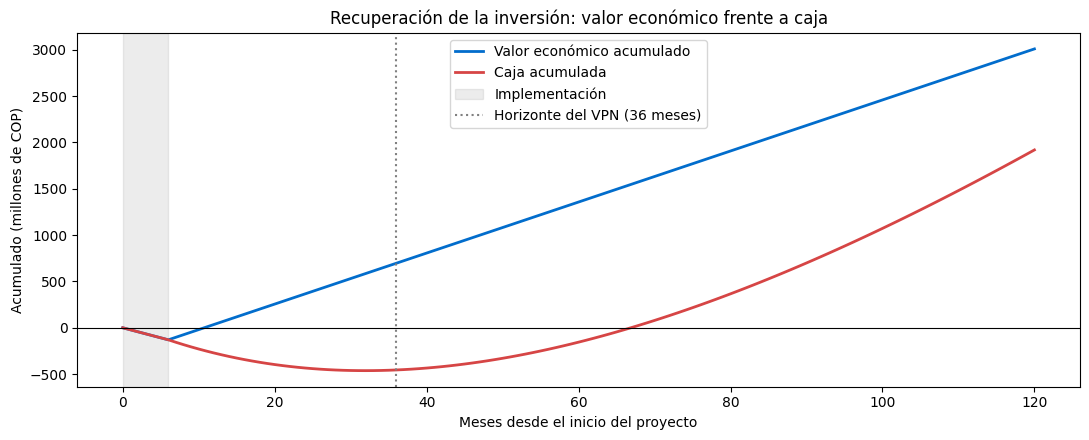

In [9]:
meses = np.arange(0, 121)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(meses, np.append(0, np.cumsum(valor_120)) / 1e6, color="#026DCC", linewidth=2, label="Valor económico acumulado")
ax.plot(meses, np.append(0, caja_acumulada) / 1e6, color="#D64545", linewidth=2, label="Caja acumulada")
ax.axvspan(0, SUPUESTOS["meses_implementacion"], color="gray", alpha=0.15, label="Implementación")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(HORIZONTE, color="gray", linestyle=":", label="Horizonte del VPN (36 meses)")
ax.set_xlabel("Meses desde el inicio del proyecto")
ax.set_ylabel("Acumulado (millones de COP)")
ax.set_title("Recuperación de la inversión: valor económico frente a caja")
ax.legend()
plt.tight_layout()
plt.show()

* Descontando la operación, el beneficio neto es de **COP 330,4 M al año** (COP 16.518 por cliente evaluado) y el **VPN a 3 años es de COP 507,7 M**.
* **En valor económico, la inversión se recupera en el mes 11.**
* **En caja, se recupera en el mes 67**, unos 5 años y medio. Los contactos se pagan de inmediato (COP 285 M al año), mientras que el margen de un cliente retenido (COP 245.000 al año) llega a lo largo de varios años. La caja acumulada toca fondo en el mes 32, con −COP 462,5 M, y desde ahí sube porque los clientes retenidos se van sumando.

**Punto de equilibrio por supuesto.** Valor de cada supuesto con el que el VPN a 3 años llega a cero. Se mueve uno a la vez y el umbral se vuelve a elegir en validación.

In [10]:
tpr_val, fpr_val = tasas_por_umbral(y_val, prob_val["Random Forest"])
tpr_test, fpr_test = tasas_por_umbral(y_test, prob_test["Random Forest"])


def resultado(sup):
    """Elige el umbral en validación con estos supuestos, evalúa en prueba y calcula el VPN a 3 años."""
    mejor = np.argmax(evaluar_campana(tpr_val, fpr_val, sup)["ganancia"])
    campana = evaluar_campana(tpr_test[mejor], fpr_test[mejor], sup)
    flujo = flujo_mensual(campana, sup, HORIZONTE)
    return {"umbral": UMBRALES[mejor], "vpn": vpn(flujo, sup["tasa_descuento"])}


def punto_equilibrio(supuesto, valores):
    """Primer valor de la lista con el que el VPN a 3 años deja de ser positivo."""
    for valor in valores:
        sup = dict(SUPUESTOS)
        sup[supuesto] = valor
        if resultado(sup)["vpn"] <= 0:
            return valor
    return None


clientes_eq = punto_equilibrio("n_clientes", range(20_000, 0, -1))
costo_eq = punto_equilibrio("costo_contacto", range(40_000, 300_001, 100))
exito_eq = punto_equilibrio("tasa_exito", np.arange(0.300, 0, -0.001))

pd.DataFrame({
    "caso base": [miles(SUPUESTOS["n_clientes"]), "COP " + miles(SUPUESTOS["costo_contacto"]), porcentaje(SUPUESTOS["tasa_exito"])],
    "punto de equilibrio": [miles(clientes_eq), "COP " + miles(costo_eq), porcentaje(exito_eq)],
}, index=["Clientes del banco", "Costo por contacto", "Efectividad de la oferta"])

,caso base,punto de equilibrio
Clientes del banco,20.000,6.047
Costo por contacto,COP 40.000,COP 135.400
Efectividad de la oferta,"30,0%","14,6%"


* **Tamaño del banco:** el modelo se paga desde unos **6.047 clientes**. Sus costos son fijos y un banco más pequeño no alcanza a cubrirlos.
* **Costo por contacto:** el VPN sigue positivo hasta unos **COP 135.400** por contacto, más del triple del caso base.
* **Efectividad de la oferta:** basta con que la oferta convenza al **14,6%** de los clientes en riesgo, la mitad de lo supuesto.

### 5.8 Sensibilidad

1. **Tornado:** cada supuesto en su valor bajo y en su valor alto, uno a la vez.
2. **Monte Carlo:** 10.000 combinaciones de todos los supuestos a la vez, cada uno con una distribución triangular (bajo, base, alto).

En los dos, el umbral se vuelve a elegir para cada combinación de supuestos.

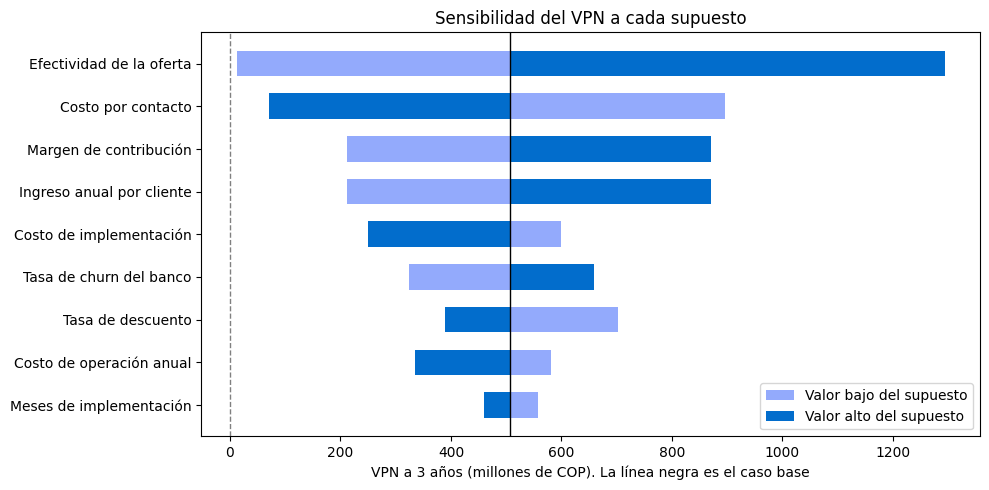

VPN del caso base: COP 507,7 M


,VPN con el valor bajo (M COP),VPN con el valor alto (M COP)
supuesto,,
Efectividad de la oferta,12.3,1293.6
Costo por contacto,896.3,70.2
Margen de contribución,211.9,871.3
Ingreso anual por cliente,211.9,871.3
Costo de implementación,598.5,249.4
Tasa de churn del banco,324.7,658.0
Tasa de descuento,702.5,389.3
Costo de operación anual,580.4,335.5
Meses de implementación,557.4,459.2


In [11]:
NOMBRES = {
    "tasa_churn": "Tasa de churn del banco",
    "tasa_exito": "Efectividad de la oferta",
    "ingreso_anual": "Ingreso anual por cliente",
    "margen": "Margen de contribución",
    "tasa_descuento": "Tasa de descuento",
    "costo_contacto": "Costo por contacto",
    "costo_implementacion": "Costo de implementación",
    "meses_implementacion": "Meses de implementación",
    "costo_operacion_anual": "Costo de operación anual",
}

vpn_base = resultado(SUPUESTOS)["vpn"]
filas = []
for supuesto, (bajo, alto) in RANGOS.items():
    sup_bajo = dict(SUPUESTOS)
    sup_bajo[supuesto] = bajo
    sup_alto = dict(SUPUESTOS)
    sup_alto[supuesto] = alto
    filas.append({
        "supuesto": NOMBRES[supuesto],
        "VPN con el valor bajo (M COP)": resultado(sup_bajo)["vpn"] / 1e6,
        "VPN con el valor alto (M COP)": resultado(sup_alto)["vpn"] / 1e6,
    })
tornado = pd.DataFrame(filas).set_index("supuesto")
tornado["diferencia"] = (tornado["VPN con el valor alto (M COP)"] - tornado["VPN con el valor bajo (M COP)"]).abs()
tornado = tornado.sort_values("diferencia")

base = vpn_base / 1e6
posiciones = np.arange(len(tornado))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(posiciones, tornado["VPN con el valor bajo (M COP)"] - base, left=base, height=0.6, color="#93AAFC", label="Valor bajo del supuesto")
ax.barh(posiciones, tornado["VPN con el valor alto (M COP)"] - base, left=base, height=0.6, color="#026DCC", label="Valor alto del supuesto")
ax.axvline(base, color="black", linewidth=1)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(posiciones)
ax.set_yticklabels(tornado.index)
ax.set_xlabel("VPN a 3 años (millones de COP). La línea negra es el caso base")
ax.set_title("Sensibilidad del VPN a cada supuesto")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("VPN del caso base:", millones(vpn_base))
tornado.drop(columns="diferencia").iloc[::-1].round(1)

* Lo que más mueve el VPN es la **efectividad de la oferta** (de COP 12 M a 1.294 M) y luego el **costo por contacto**. Los dos dependen de la campaña, no del modelo.
* El margen y el ingreso tienen el mismo efecto, porque los dos multiplican el CLV.
* Los costos del modelo pesan menos: con una implementación de COP 400 M, el VPN sigue en COP 249 M.
* Ningún supuesto, solo y dentro de su rango, deja el VPN negativo.

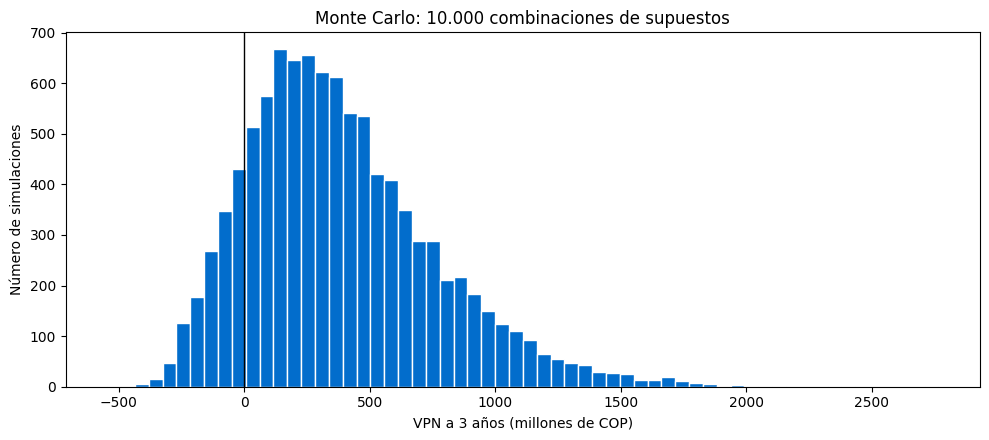

,Monte Carlo
"VPN, mediana","COP 328,5 M"
"VPN, percentil 5","COP -130,7 M"
"VPN, percentil 95","COP 1091,9 M"
Probabilidad de VPN positivo,"86,2%"
Probabilidad de superar la mejor opción sin modelo,"76,2%"


In [12]:
def vpn_sin_modelo(sup):
    """VPN a 3 años de la mejor opción sin modelo: no hacer campaña (0) o contactar a todos desde el mes 1."""
    todos = evaluar_campana(1.0, 1.0, sup)
    flujo = np.full(HORIZONTE, todos["ganancia"] / 12)
    return max(0, vpn(flujo, sup["tasa_descuento"]))


M = 10_000
rng = np.random.default_rng(SEED)
vpn_mc = []
vpn_alternativa_mc = []
for i in range(M):
    sup = dict(SUPUESTOS)
    for supuesto, (bajo, alto) in RANGOS.items():
        sup[supuesto] = rng.triangular(bajo, SUPUESTOS[supuesto], alto)
    sup["meses_implementacion"] = round(sup["meses_implementacion"])
    vpn_mc.append(resultado(sup)["vpn"])
    vpn_alternativa_mc.append(vpn_sin_modelo(sup))
vpn_mc = np.array(vpn_mc)
vpn_alternativa_mc = np.array(vpn_alternativa_mc)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(vpn_mc / 1e6, bins=60, color="#026DCC", edgecolor="white")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("VPN a 3 años (millones de COP)")
ax.set_ylabel("Número de simulaciones")
ax.set_title(f"Monte Carlo: {miles(M)} combinaciones de supuestos")
plt.tight_layout()
plt.show()

pd.Series({
    "VPN, mediana": millones(np.median(vpn_mc)),
    "VPN, percentil 5": millones(np.percentile(vpn_mc, 5)),
    "VPN, percentil 95": millones(np.percentile(vpn_mc, 95)),
    "Probabilidad de VPN positivo": porcentaje((vpn_mc > 0).mean()),
    "Probabilidad de superar la mejor opción sin modelo": porcentaje((vpn_mc > vpn_alternativa_mc).mean()),
}).to_frame("Monte Carlo")

* El VPN es positivo en el **86,2%** de las simulaciones, con una mediana de COP 328,5 M.
* El modelo supera a la mejor opción sin modelo en el **76,2%**. El resto son escenarios en los que contactar es tan barato que conviene contactar a todos sin modelo.
* La mediana es menor que el caso base porque varios rangos se extienden más hacia el lado desfavorable, como la implementación (de 35 M a 400 M, con base de 130 M).

### 5.9 Limitaciones

1. **Los datos no son colombianos.** El modelo se entrenó con clientes de Francia, Alemania y España. Hay que reentrenarlo y validarlo con datos del banco antes de usarlo.
2. **El ajuste de 20% a 15%** supone que los clientes que se van, y los que se quedan, se parecen en los dos bancos.
3. **El modelo predice riesgo, no persuasión.** Suponemos que la oferta convence al 30% de cualquier cliente en riesgo, pero los de mayor riesgo pueden ser los menos persuadibles ([Ascarza, 2018](https://www.ama.org/press-releases/eva-ascarza-receives-2023-weitz-winer-odell-award-for-retention-futility/)). Solo un experimento con grupo de control lo mide.
4. **El CLV simplifica.** Supone margen y churn constantes, y que el cliente retenido se comporta como uno promedio. Si vuelve a tener un riesgo alto, vale menos.
5. **La caja tarda.** En valor económico el modelo se paga en el mes 11, pero el dinero vuelve en el mes 67. El banco tiene que poder financiar esa diferencia.
6. **Algunos supuestos tienen fuentes débiles.** El 15% de churn no tiene un estudio detrás, el costo por contacto depende de precios de proveedores, y los contactos por hora y el costo de nube son nuestros. Tampoco encontramos cuánto gana Nu por cliente en Colombia.
7. **El modelo se degrada.** Suponemos el mismo desempeño durante 3 años. En la práctica hay que monitorearlo y reentrenarlo.
8. **Aspectos legales y éticos.** El banco necesita autorización para usar los datos (Ley 1581 de 2012) y debe respetar los horarios y canales de contacto ([Ley 2300 de 2023](https://www.funcionpublica.gov.co/eva/gestornormativo/norma.php?i=213990)). El modelo usa el género y la edad, así que hay que revisar que la campaña no discrimine.

### 5.10 Conclusiones

**Ganancia.** En un banco de 20.000 clientes con 15% de churn, el Random Forest con umbral 0,30:
* retiene a unos **734 clientes al año** y baja el churn de 15% a 11,3%;
* deja **COP 380 M al año** en la campaña (intervalo de 95% entre 349 M y 410 M), es decir, **COP 19.018 por cliente evaluado**; descontando la operación del modelo, COP 330 M (COP 16.518 por cliente);
* sin modelo, la mejor opción es contactar a todos, que deja COP 15,5 M.

**Punto de equilibrio.** Con COP 130 M de implementación y COP 50 M al año de operación:
* en valor económico, la inversión se recupera en el **mes 11** y el **VPN a 3 años es de COP 508 M**;
* en caja, se recupera en el **mes 67**;
* el VPN sigue positivo mientras el banco tenga más de 6.047 clientes, el contacto cueste menos de COP 135.400 y la oferta convenza a más del 14,6% (cada condición por separado).

**Riesgo.** El VPN es positivo en el 86% de las simulaciones, y el modelo supera a la mejor opción sin modelo en el 76%. El riesgo está en la campaña (efectividad y costo del contacto), no en el modelo.

**Recomendaciones**
1. **Hacer un piloto con grupo de control** para medir la efectividad real de la oferta, que es el supuesto que más pesa.
2. **Reentrenar y validar el modelo con datos del banco** antes de escalar.
3. **Recalcular el umbral con los costos reales.** En el caso base, 0,30 y 0,5 dan una ganancia parecida; el umbral importa más cuando cambian los costos o la oferta.
4. **Elegir el canal y el incentivo con este mismo análisis**, porque mueven el resultado más que el modelo.
5. **Planear la caja:** el dinero invertido vuelve en unos 5 años y medio.